# Stage 03: Statistical Analysis & Hypothesis Testing
## Hotel Booking Cancellation Prediction

### Grounding in FSMVU Data Science Course Curriculum
This notebook provides a comprehensive, curriculum-grounded inferential and descriptive statistical analysis of the hotel booking cancellation dataset. It bridges foundational statistical theory with empirical business intelligence to rigorously determine which customer behaviors, operational parameters, and contractual policies drive cancellation risk.

### Core Curricular Components:
1. **Descriptive Statistics & Distribution Shapes:**
   * Central tendency (Mean vs. Median) and dispersion (Standard Deviation vs. Interquartile Range).
   * Higher-order distribution moments: Fisher-Pearson coefficient of skewness ($g_1$) and excess kurtosis ($g_2$).
   * Demonstrating how extreme skewness invalidates sample mean as a robust central metric.
2. **Hypothesis Testing for Categorical Features (Contingency Analysis):**
   * Pearson's Chi-Square Test of Independence ($\chi^2$) across nominal and ordinal predictors.
   * Quantifying practical magnitude with Cramér's V effect size to separate genuine business impact from sample-size-driven statistical significance.
3. **Hypothesis Testing for Continuous Features (Difference in Distributions):**
   * Formulating $H_0$ and $H_1$ for booking lead time and average daily rate across canceled and non-canceled reservations.
   * Addressing heteroscedasticity and non-normality: Welch's two-sample t-test alongside the non-parametric Mann-Whitney U test.
   * Calculating standardized effect sizes: Cohen's $d$ and Rank Biserial Correlation ($r_{rb}$).
4. **Correlation Analysis (Linear vs. Monotonic):**
   * Contrasting Pearson linear correlation ($r$) with Spearman rank-order correlation ($\rho$) to identify non-linear monotonic relationships.
   * Explaining why zero-inflated operational variables (e.g., previous cancellations, special requests) are severely understated by linear correlation.
5. **Unified Statistical Summary Table:**
   * Compiling all statistical tests, statistics, degrees of freedom, p-values, effect sizes, decisions, and domain implications into a standardized table exported to `results/tables/statistical_tests.csv`.
6. **Key Statistical Takeaways for Preprocessing & Modeling:**
   * Synthesizing findings to guide feature selection, transformation choices, and algorithm family decisions in subsequent phases.

---
### Pedagogical Framework
Every analytical section in this notebook strictly follows the three-part pedagogical format:
* **What we are doing:** Technical description of the methodology, test formulation, and computational process.
* **Why we are doing it:** Theoretical rationale, mathematical justification, and assumption verification from first principles.
* **What the output means:** Empirical interpretation of statistics, p-values, effect sizes, and their real-world hospitality domain significance.

### 1. Environment Setup, Imports, and Data Ingestion

* **What we are doing:** Importing numerical computing (`numpy`, `pandas`), statistical testing (`scipy.stats`), and visualization (`matplotlib`, `seaborn`) libraries. Loading `hotel_bookings.csv` and applying domain anomaly cleaning established in Stages 01 and 02.
* **Why we are doing it:** Hypothesis tests—especially parametric tests such as Welch's t-test and Pearson correlation—are sensitive to data entry errors and nonsensical records. Removing 180 "ghost bookings" (0 adults, 0 children, 0 babies) and 2 ADR pricing typos (-$6.38 and $5,400.00) ensures mathematical validity and prevents corrupted variance estimates.
* **What the output means:** Confirmation of environment configuration, directory verification for saved artifacts, and clean baseline dataset ready for statistical evaluation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats.contingency import association
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Configure display and plot settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.4f}'.format)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 150

# Output directories
fig_dir = Path("results/figures") if Path("results/figures").exists() else Path("../results/figures")
table_dir = Path("results/tables") if Path("results/tables").exists() else Path("../results/tables")
fig_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

# Load data
data_path = Path("data/raw/hotel_bookings.csv") if Path("data/raw/hotel_bookings.csv").exists() else Path("../data/raw/hotel_bookings.csv")
df_raw = pd.read_csv(data_path)
print(f"Raw dataset loaded: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")

# Basic anomaly cleaning (Ghost bookings and ADR errors)
has_guests = (df_raw['adults'] + df_raw['children'].fillna(0) + df_raw['babies']) > 0
valid_adr = (df_raw['adr'] >= 0) & (df_raw['adr'] < 1000)
df = df_raw[has_guests & valid_adr].copy()

removed_count = len(df_raw) - len(df)
print(f"Cleaned records remaining: {len(df):,} ({len(df)/len(df_raw)*100:.2f}%)")
print(f"Anomalous records filtered: {removed_count:,} (180 ghost bookings, 2 ADR pricing errors)")

Raw dataset loaded: 119,390 rows, 32 columns
Cleaned records remaining: 119,208 (99.85%)
Anomalous records filtered: 182 (180 ghost bookings, 2 ADR pricing errors)


### 2. Descriptive Statistics & Distribution Shapes

* **What we are doing:** Computing fundamental summary statistics and higher-order distribution moments for key numerical features: `lead_time`, `adr`, `total_of_special_requests`, `stays_in_week_nights`, and `stays_in_weekend_nights`. Specifically, we evaluate the Mean, Median, Standard Deviation, Interquartile Range ($IQR = Q_3 - Q_1$), Skewness ($g_1$), and Excess Kurtosis ($g_2$).
* **Why we are doing it:** In the FSMVU Data Science curriculum, descriptive analysis is the prerequisite first step before inferential testing. 
  1. **Mean vs. Median:** The mean $\bar{x} = \frac{1}{n}\sum x_i$ represents the gravitational center of the distribution but is highly sensitive to extreme outliers. The median ($Q_2$) represents the 50th percentile and is robust against extreme values. When $\bar{x} > \text{median}$, the distribution has a positive (right) skew.
  2. **Standard Deviation vs. IQR:** Standard deviation ($s = \sqrt{\frac{1}{n-1}\sum(x_i - \bar{x})^2}$) measures parametric dispersion around the mean, while IQR measures the range containing the central 50% of observations, offering an outlier-resistant metric.
  3. **Skewness ($g_1$):** Measures distributional asymmetry:
     $$g_1 = \frac{\frac{1}{n}\sum (x_i - \bar{x})^3}{\left(\frac{1}{n}\sum (x_i - \bar{x})^2\right)^{3/2}}$$
     $g_1 > 0$ indicates a prolonged right tail; $|g_1| > 1.0$ indicates substantial skewness.
  4. **Excess Kurtosis ($g_2$):** Measures tail-heaviness and outlier propensity relative to a standard normal distribution ($g_2 = 0$):
     $$g_2 = \frac{\frac{1}{n}\sum (x_i - \bar{x})^4}{\left(\frac{1}{n}\sum (x_i - \bar{x})^2\right)^2} - 3$$
     $g_2 > 0$ indicates a leptokurtic distribution characterized by fat tails and higher probability of extreme events.
* **What the output means:** The table below quantifies the degree of non-normality across all key operational metrics, indicating which features require robust non-parametric testing or transformation.

In [2]:
key_num_cols = [
    'lead_time', 
    'adr', 
    'total_of_special_requests', 
    'stays_in_week_nights', 
    'stays_in_weekend_nights'
]

desc_records = []
for col in key_num_cols:
    series = df[col].dropna()
    mean_val = series.mean()
    median_val = series.median()
    std_val = series.std()
    q25 = series.quantile(0.25)
    q75 = series.quantile(0.75)
    iqr_val = q75 - q25
    skew_val = series.skew()
    kurt_val = series.kurtosis()
    diff_val = mean_val - median_val
    
    desc_records.append({
        'Feature': col,
        'Mean': mean_val,
        'Median': median_val,
        'Std Dev': std_val,
        'IQR (Q3-Q1)': iqr_val,
        'Skewness (g1)': skew_val,
        'Kurtosis (g2)': kurt_val,
        'Mean - Median': diff_val,
        'Distribution Shape': 'Substantial Right Skew' if skew_val > 1.0 else ('Moderate Right Skew' if skew_val > 0.5 else 'Symmetric')
    })

desc_df = pd.DataFrame(desc_records)
print("=== NUMERICAL DESCRIPTIVE STATISTICS & DISTRIBUTION MOMENTS ===")
desc_df

=== NUMERICAL DESCRIPTIVE STATISTICS & DISTRIBUTION MOMENTS ===

,Feature,Mean,Median,Std Dev,IQR (Q3-Q1),Skewness (g1),Kurtosis (g2),Mean - Median,Distribution Shape
0,lead_time,104.1090,69.0000,106.8758,143.0000,1.3458,1.6944,35.1090,Substantial Right Skew
1,adr,101.9256,94.9500,48.0423,56.5000,1.0303,2.1483,6.9756,Substantial Right Skew
2,total_of_special_requests,0.5715,0.0000,0.7929,1.0000,1.3490,1.4925,0.5715,Substantial Right Skew
3,stays_in_week_nights,2.4992,2.0000,1.8971,2.0000,2.7550,22.2521,0.4992,Substantial Right Skew
4,stays_in_weekend_nights,0.9270,1.0000,0.9951,2.0000,1.3202,6.3662,-0.0730,Substantial Right Skew


### 2.1 Distribution Shape Visualizations: Histograms, KDE, and Skewness

* **What we are doing:** Constructing distribution plots combining Kernel Density Estimation (KDE) and overlaid vertical lines for the Mean (dashed red) and Median (dashed green), accompanied by corresponding boxplots for each key feature.
* **Why we are doing it:** Graphical examination provides immediate visual proof of the mathematical skewness and tail fatness calculated above, illustrating the separation between mean and median.
* **What the output means:** For `lead_time`, the distribution is heavily skewed ($g_1 = 1.35$) with a median of 69 days and a mean of 104.1 days (a gap of +35.1 days). This demonstrates that while half of all bookings are made within ~2 months, long-tail reservations made 300 to 700 days in advance drag the sample mean dramatically upward. Similar right-skew patterns emerge for `stays_in_week_nights` ($g_1 = 2.75$, $g_2 = 22.25$), proving severe leptokurtic behavior.

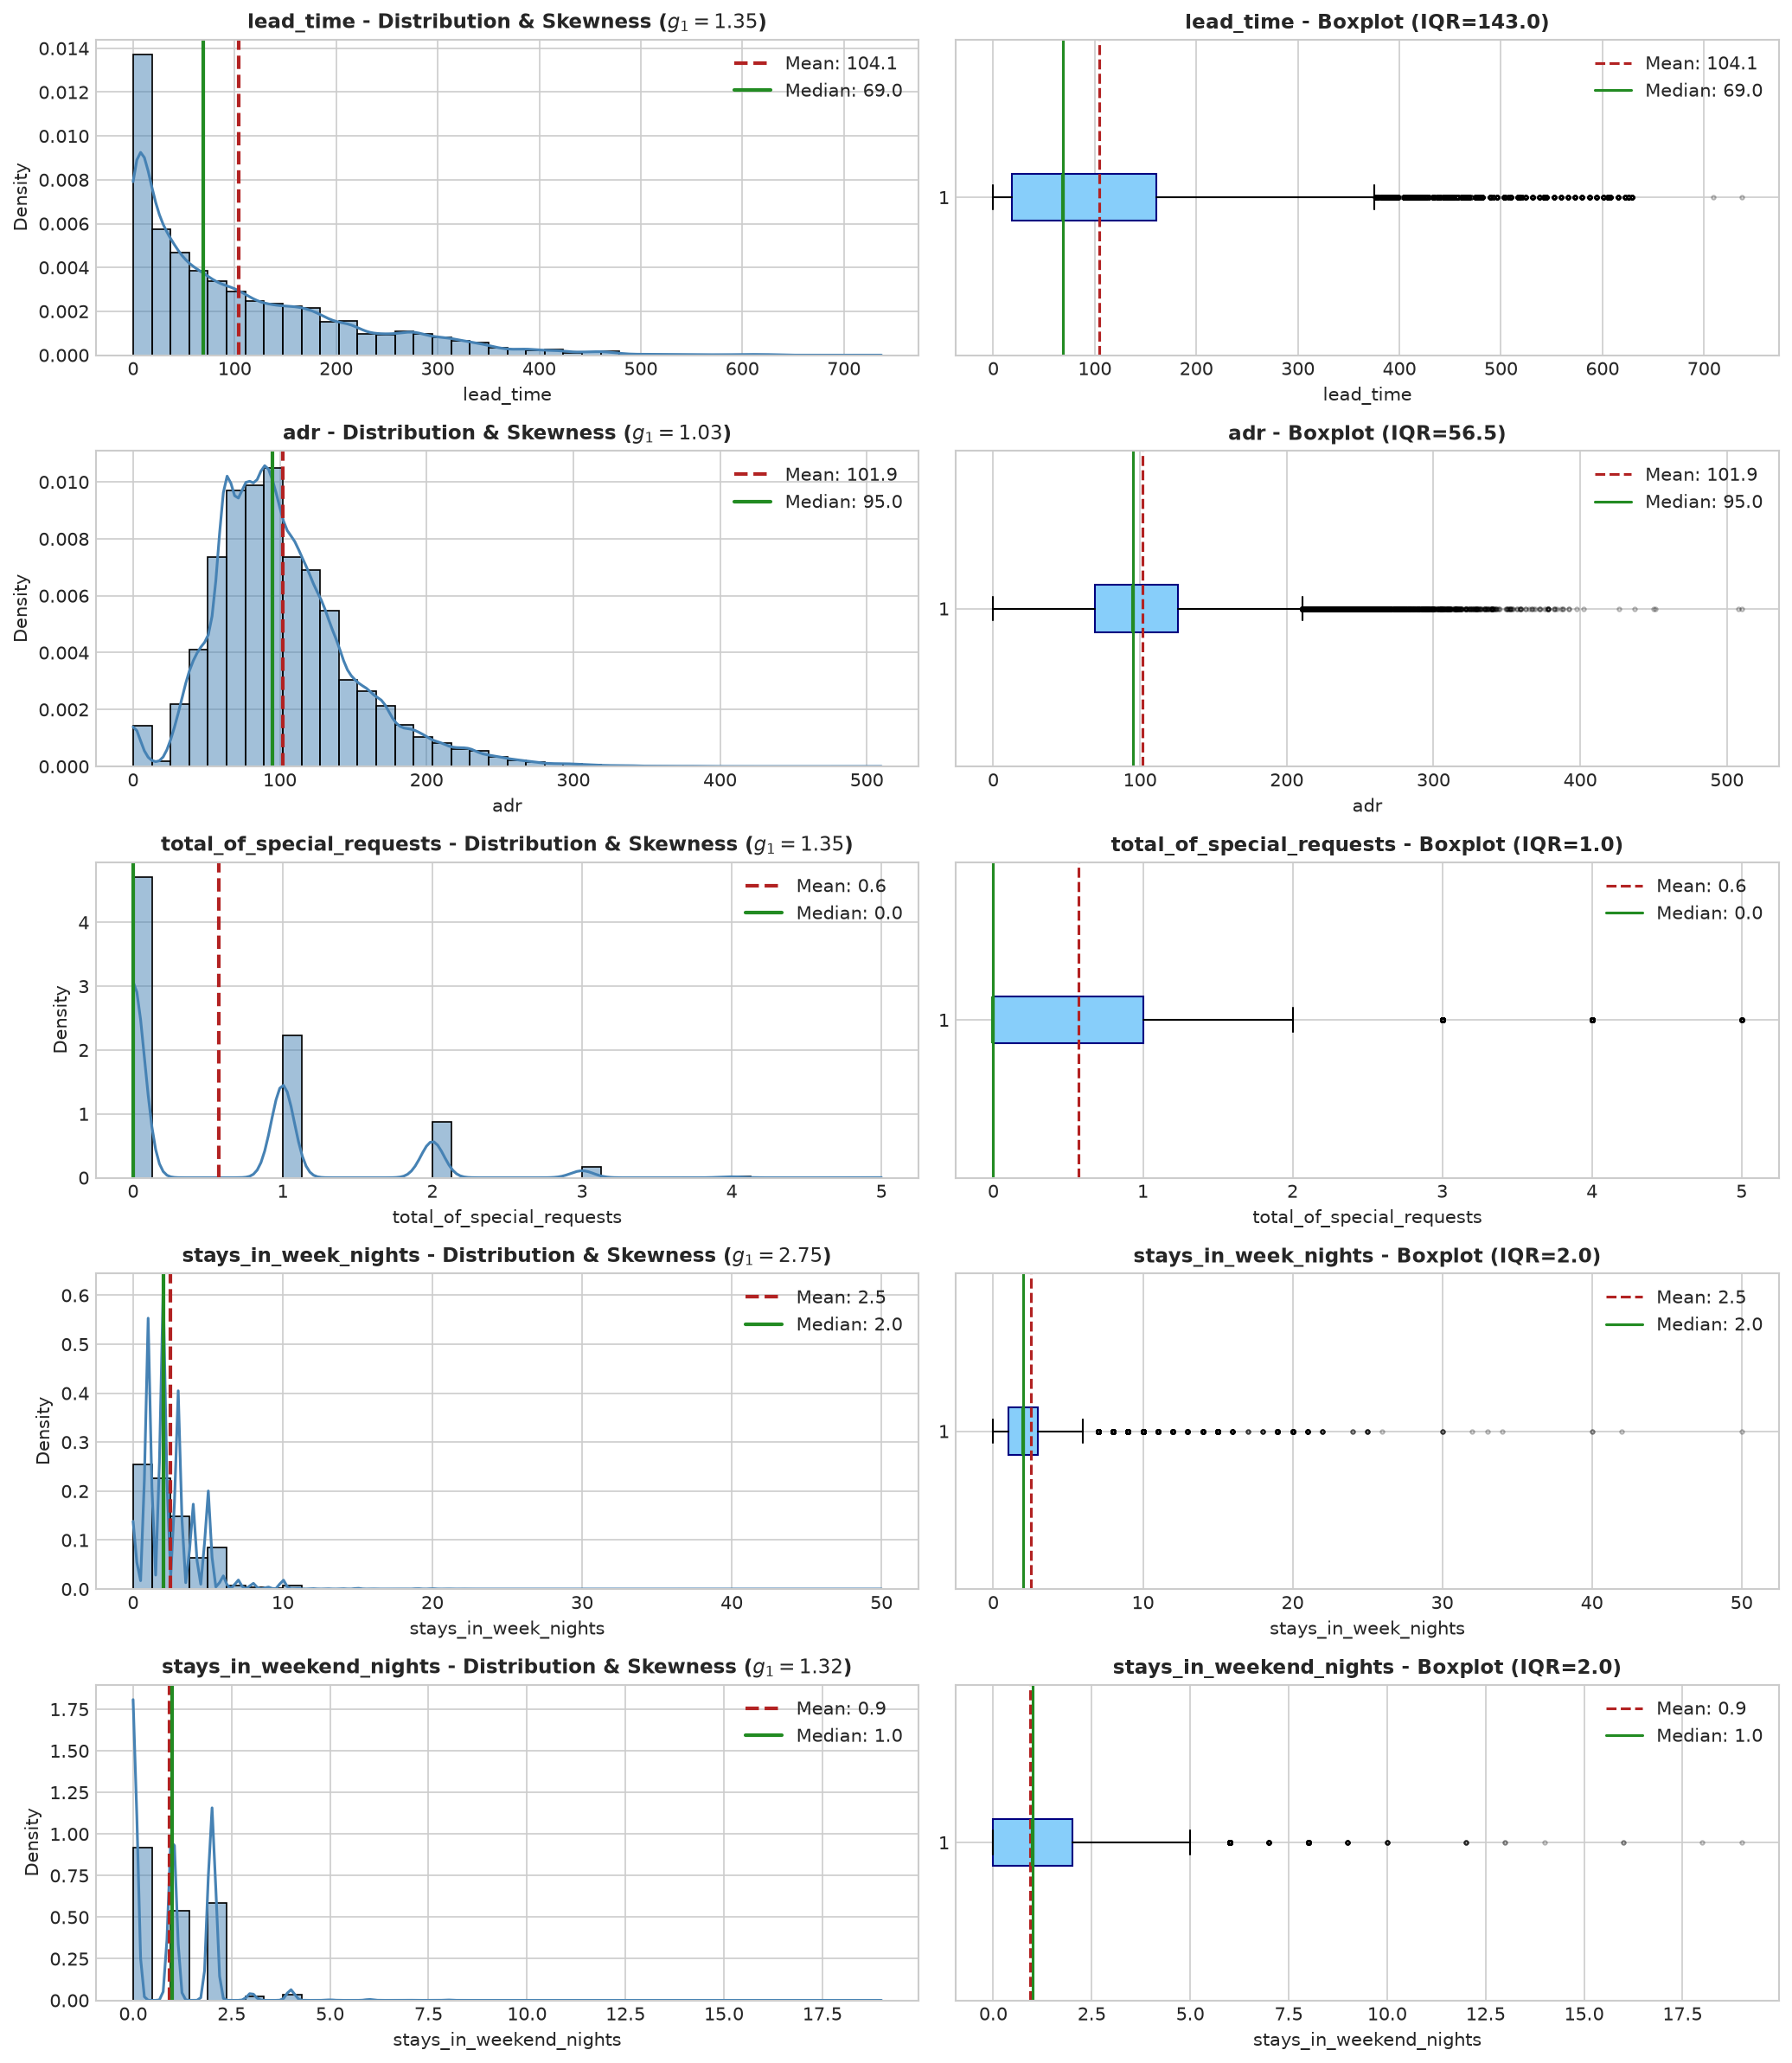

Saved figure to: results\figures\03_descriptive_distributions.png


In [3]:
fig, axes = plt.subplots(len(key_num_cols), 2, figsize=(14, 16))

for i, col in enumerate(key_num_cols):
    data = df[col].dropna()
    mean_v = data.mean()
    median_v = data.median()
    
    # 1. Histogram + KDE
    ax_hist = axes[i, 0]
    sns.histplot(data, kde=True, ax=ax_hist, color='steelblue', bins=40, stat='density', alpha=0.5)
    ax_hist.axvline(mean_v, color='firebrick', linestyle='--', linewidth=2, label=f'Mean: {mean_v:.1f}')
    ax_hist.axvline(median_v, color='forestgreen', linestyle='-', linewidth=2, label=f'Median: {median_v:.1f}')
    ax_hist.set_title(f"{col} - Distribution & Skewness ($g_1={data.skew():.2f}$)", fontsize=11, fontweight='bold')
    ax_hist.set_xlabel(col)
    ax_hist.set_ylabel('Density')
    ax_hist.legend(loc='upper right')
    
    # 2. Boxplot (Matplotlib native for robust rendering)
    ax_box = axes[i, 1]
    ax_box.boxplot(
        data, 
        vert=False, 
        patch_artist=True,
        boxprops=dict(facecolor='lightskyblue', color='navy'),
        medianprops=dict(color='forestgreen', linewidth=2),
        flierprops=dict(marker='o', markersize=2, alpha=0.3, color='steelblue')
    )
    ax_box.axvline(mean_v, color='firebrick', linestyle='--', linewidth=1.5, label=f'Mean: {mean_v:.1f}')
    ax_box.axvline(median_v, color='forestgreen', linestyle='-', linewidth=1.5, label=f'Median: {median_v:.1f}')
    ax_box.set_title(f"{col} - Boxplot (IQR={data.quantile(0.75)-data.quantile(0.25):.1f})", fontsize=11, fontweight='bold')
    ax_box.set_xlabel(col)
    ax_box.legend(loc='upper right')

plt.tight_layout()
fig_path = fig_dir / "03_descriptive_distributions.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved figure to: {fig_path}")

### 3. Hypothesis Testing for Categorical Features (Pearson's Chi-Square Test of Independence)

* **What we are doing:** Performing Pearson's Chi-Square Test of Independence ($\chi^2$) and computing Cramér's V effect size to test for associations between categorical predictors (`deposit_type`, `market_segment`, `distribution_channel`, `hotel`, and `customer_type`) and booking cancellation (`is_canceled`).
* **Why we are doing it:**
  * **Categorical Scale:** When analyzing associations between two categorical (nominal or ordinal) variables, continuous correlation metrics like Pearson's $r$ are inappropriate. The Chi-Square test evaluates two-way contingency tables ($r \times c$) by comparing observed cell frequencies ($O_{ij}$) against theoretical expected frequencies ($E_{ij}$) under the null hypothesis of independence:
    $$E_{ij} = \frac{R_i \cdot C_j}{N}$$
    $$\chi^2 = \sum_{i=1}^r \sum_{j=1}^c \frac{(O_{ij} - E_{ij})^2}{E_{ij}}, \quad \text{with } df = (r - 1)(c - 1)$$
  * **Hypothesis Formulation:**
    * **Null Hypothesis ($H_0$):** There is no association between the categorical feature and booking cancellation (the two variables are statistically independent: $P(A \cap B) = P(A)P(B)$).
    * **Alternative Hypothesis ($H_1$):** There is a statistically significant association between the categorical feature and booking cancellation.
  * **The "Large $N$" Caveat & Effect Size (Cramér's V):** With our dataset containing $N = 119,208$ observations, even minuscule, economically irrelevant differences yield vanishingly small p-values ($p < 0.001$). Therefore, statistical significance alone is insufficient to guide machine learning feature selection. We compute Cramér's V to measure the standardized effect size:
    $$V = \sqrt{\frac{\chi^2}{N \cdot \min(r - 1, c - 1)}}$$
    For our $2 \times k$ tables where $\min(2-1, k-1) = 1$, $V$ simplifies to $\sqrt{\frac{\chi^2}{N}}$.
    * **Cohen's Conventions for Cramér's V ($df^* = 1$):**
      * Small effect: $V \approx 0.10$
      * Medium effect: $V \approx 0.30$
      * Large effect: $V \ge 0.50$
* **What the output means:** The contingency tables and test statistics below determine which categorical features have high practical predictive power versus those whose significance is purely a statistical artifact of massive sample size.

In [4]:
cat_test_features = [
    'deposit_type', 
    'market_segment', 
    'distribution_channel', 
    'hotel', 
    'customer_type'
]

chi2_results = []

for feat in cat_test_features:
    # 1. Build contingency table
    ct_counts = pd.crosstab(df[feat], df['is_canceled'], margins=False)
    ct_pct = pd.crosstab(df[feat], df['is_canceled'], normalize='index') * 100
    
    # 2. Chi-square test
    chi2_stat, p_val, dof, expected = stats.chi2_contingency(ct_counts)
    
    # 3. Cramér's V
    cramer_v = association(ct_counts, method='cramer')
    
    # Qualitative effect size description
    if cramer_v >= 0.40:
        eff_desc = 'Very Large'
    elif cramer_v >= 0.25:
        eff_desc = 'Moderate to Large'
    elif cramer_v >= 0.15:
        eff_desc = 'Small to Moderate'
    else:
        eff_desc = 'Small'
        
    chi2_results.append({
        'Feature': feat,
        'Chi2 Statistic': chi2_stat,
        'Degrees of Freedom': dof,
        'p-value': p_val,
        "Cramér's V": cramer_v,
        'Effect Magnitude': eff_desc,
        'Decision (alpha=0.05)': 'Reject H0' if p_val < 0.05 else 'Fail to Reject H0'
    })
    
    # Display breakdown
    print("=" * 80)
    print(f"Contingency Table: {feat} vs. is_canceled")
    print("=" * 80)
    summary_ct = ct_counts.copy()
    summary_ct.columns = ['Not Canceled (0)', 'Canceled (1)']
    summary_ct['Cancellation Rate (%)'] = ct_pct[1]
    summary_ct['Total Bookings'] = summary_ct['Not Canceled (0)'] + summary_ct['Canceled (1)']
    print(summary_ct.to_string())
    print(f"--> Chi2 = {chi2_stat:,.2f}, df = {dof}, p-value = {p_val:.2e}, Cramér's V = {cramer_v:.4f} ({eff_desc})\n")

chi2_summary_df = pd.DataFrame(chi2_results)
print("=== CHI-SQUARE TEST OF INDEPENDENCE SUMMARY ===")
chi2_summary_df

Contingency Table: deposit_type vs. is_canceled
              Not Canceled (0)  Canceled (1)  Cancellation Rate (%)  Total Bookings
deposit_type                                                                       
No Deposit               74791         29669                28.4023          104460
Non Refund                  93         14493                99.3624           14586
Refundable                 126            36                22.2222             162
--> Chi2 = 27,639.52, df = 2, p-value = 0.00e+00, Cramér's V = 0.4815 (Very Large)



Contingency Table: market_segment vs. is_canceled
                Not Canceled (0)  Canceled (1)  Cancellation Rate (%)  Total Bookings
market_segment                                                                       
Aviation                     183            52                22.1277             235
Complementary                639            89                12.2253             728
Corporate                   4291           991                18.7618            5282
Direct                     10648          1934                15.3712           12582
Groups                      7696         12094                61.1117           19790
Offline TA/TO              15880          8301                34.3286           24181
Online TA                  35673         20735                36.7590           56408
Undefined                      0             2               100.0000               2
--> Chi2 = 8,499.93, df = 7, p-value = 0.00e+00, Cramér's V = 0.2670 (Moderate to Large)



Contingency Table: hotel vs. is_canceled
              Not Canceled (0)  Canceled (1)  Cancellation Rate (%)  Total Bookings
hotel                                                                              
City Hotel               46084         33078                41.7852           79162
Resort Hotel             28926         11120                27.7681           40046
--> Chi2 = 2,239.04, df = 1, p-value = 0.00e+00, Cramér's V = 0.1371 (Small)

Contingency Table: customer_type vs. is_canceled
                 Not Canceled (0)  Canceled (1)  Cancellation Rate (%)  Total Bookings
customer_type                                                                         
Contract                     2810          1262                30.9921            4072
Group                         516            58                10.1045             574
Transient                   52982         36493                40.7857           89475
Transient-Party             18702          6385              

,Feature,Chi2 Statistic,Degrees of Freedom,p-value,Cramér's V,Effect Magnitude,Decision (alpha=0.05)
0,deposit_type,27639.5231,2,0.0000,0.4815,Very Large,Reject H0
1,market_segment,8499.9293,7,0.0000,0.2670,Moderate to Large,Reject H0
2,distribution_channel,3741.1342,4,0.0000,0.1772,Small to Moderate,Reject H0
3,hotel,2239.0377,1,0.0000,0.1371,Small,Reject H0
4,customer_type,2224.4697,3,0.0000,0.1366,Small,Reject H0


### 3.1 Categorical Cancellation Rates and Effect Sizes Visualization

* **What we are doing:** Plotting horizontal bar charts showing the exact cancellation rate (%) for each category across all 5 evaluated features, sorting categories by risk, and annotating each subplot with its Cramér's V effect size.
* **Why we are doing it:** To communicate the managerial and operational implications of the contingency tables.
* **What the output means:**
  1. `deposit_type` ($V = 0.4815$): Almost reaches the benchmark for a "large" effect size ($V \ge 0.50$). Non-Refundable deposits have a staggering **99.36%** cancellation rate, whereas No Deposit bookings cancel at **28.38%**. As established in Phase 2, this "Deposit Paradox" occurs because hotels impose non-refundable requirements primarily on high-risk group tour operators who book speculatively and dump room blocks en masse.
  2. `market_segment` ($V = 0.2670$): Strong moderate effect size. Online TA (36.7%) and Groups (61.1%) carry substantial cancellation risk compared to Corporate (18.7%) and Direct (15.3%).
  3. `distribution_channel` ($V = 0.1772$) & `hotel` ($V = 0.1371$): City Hotels cancel at 41.7% versus Resort Hotels at 27.8%.

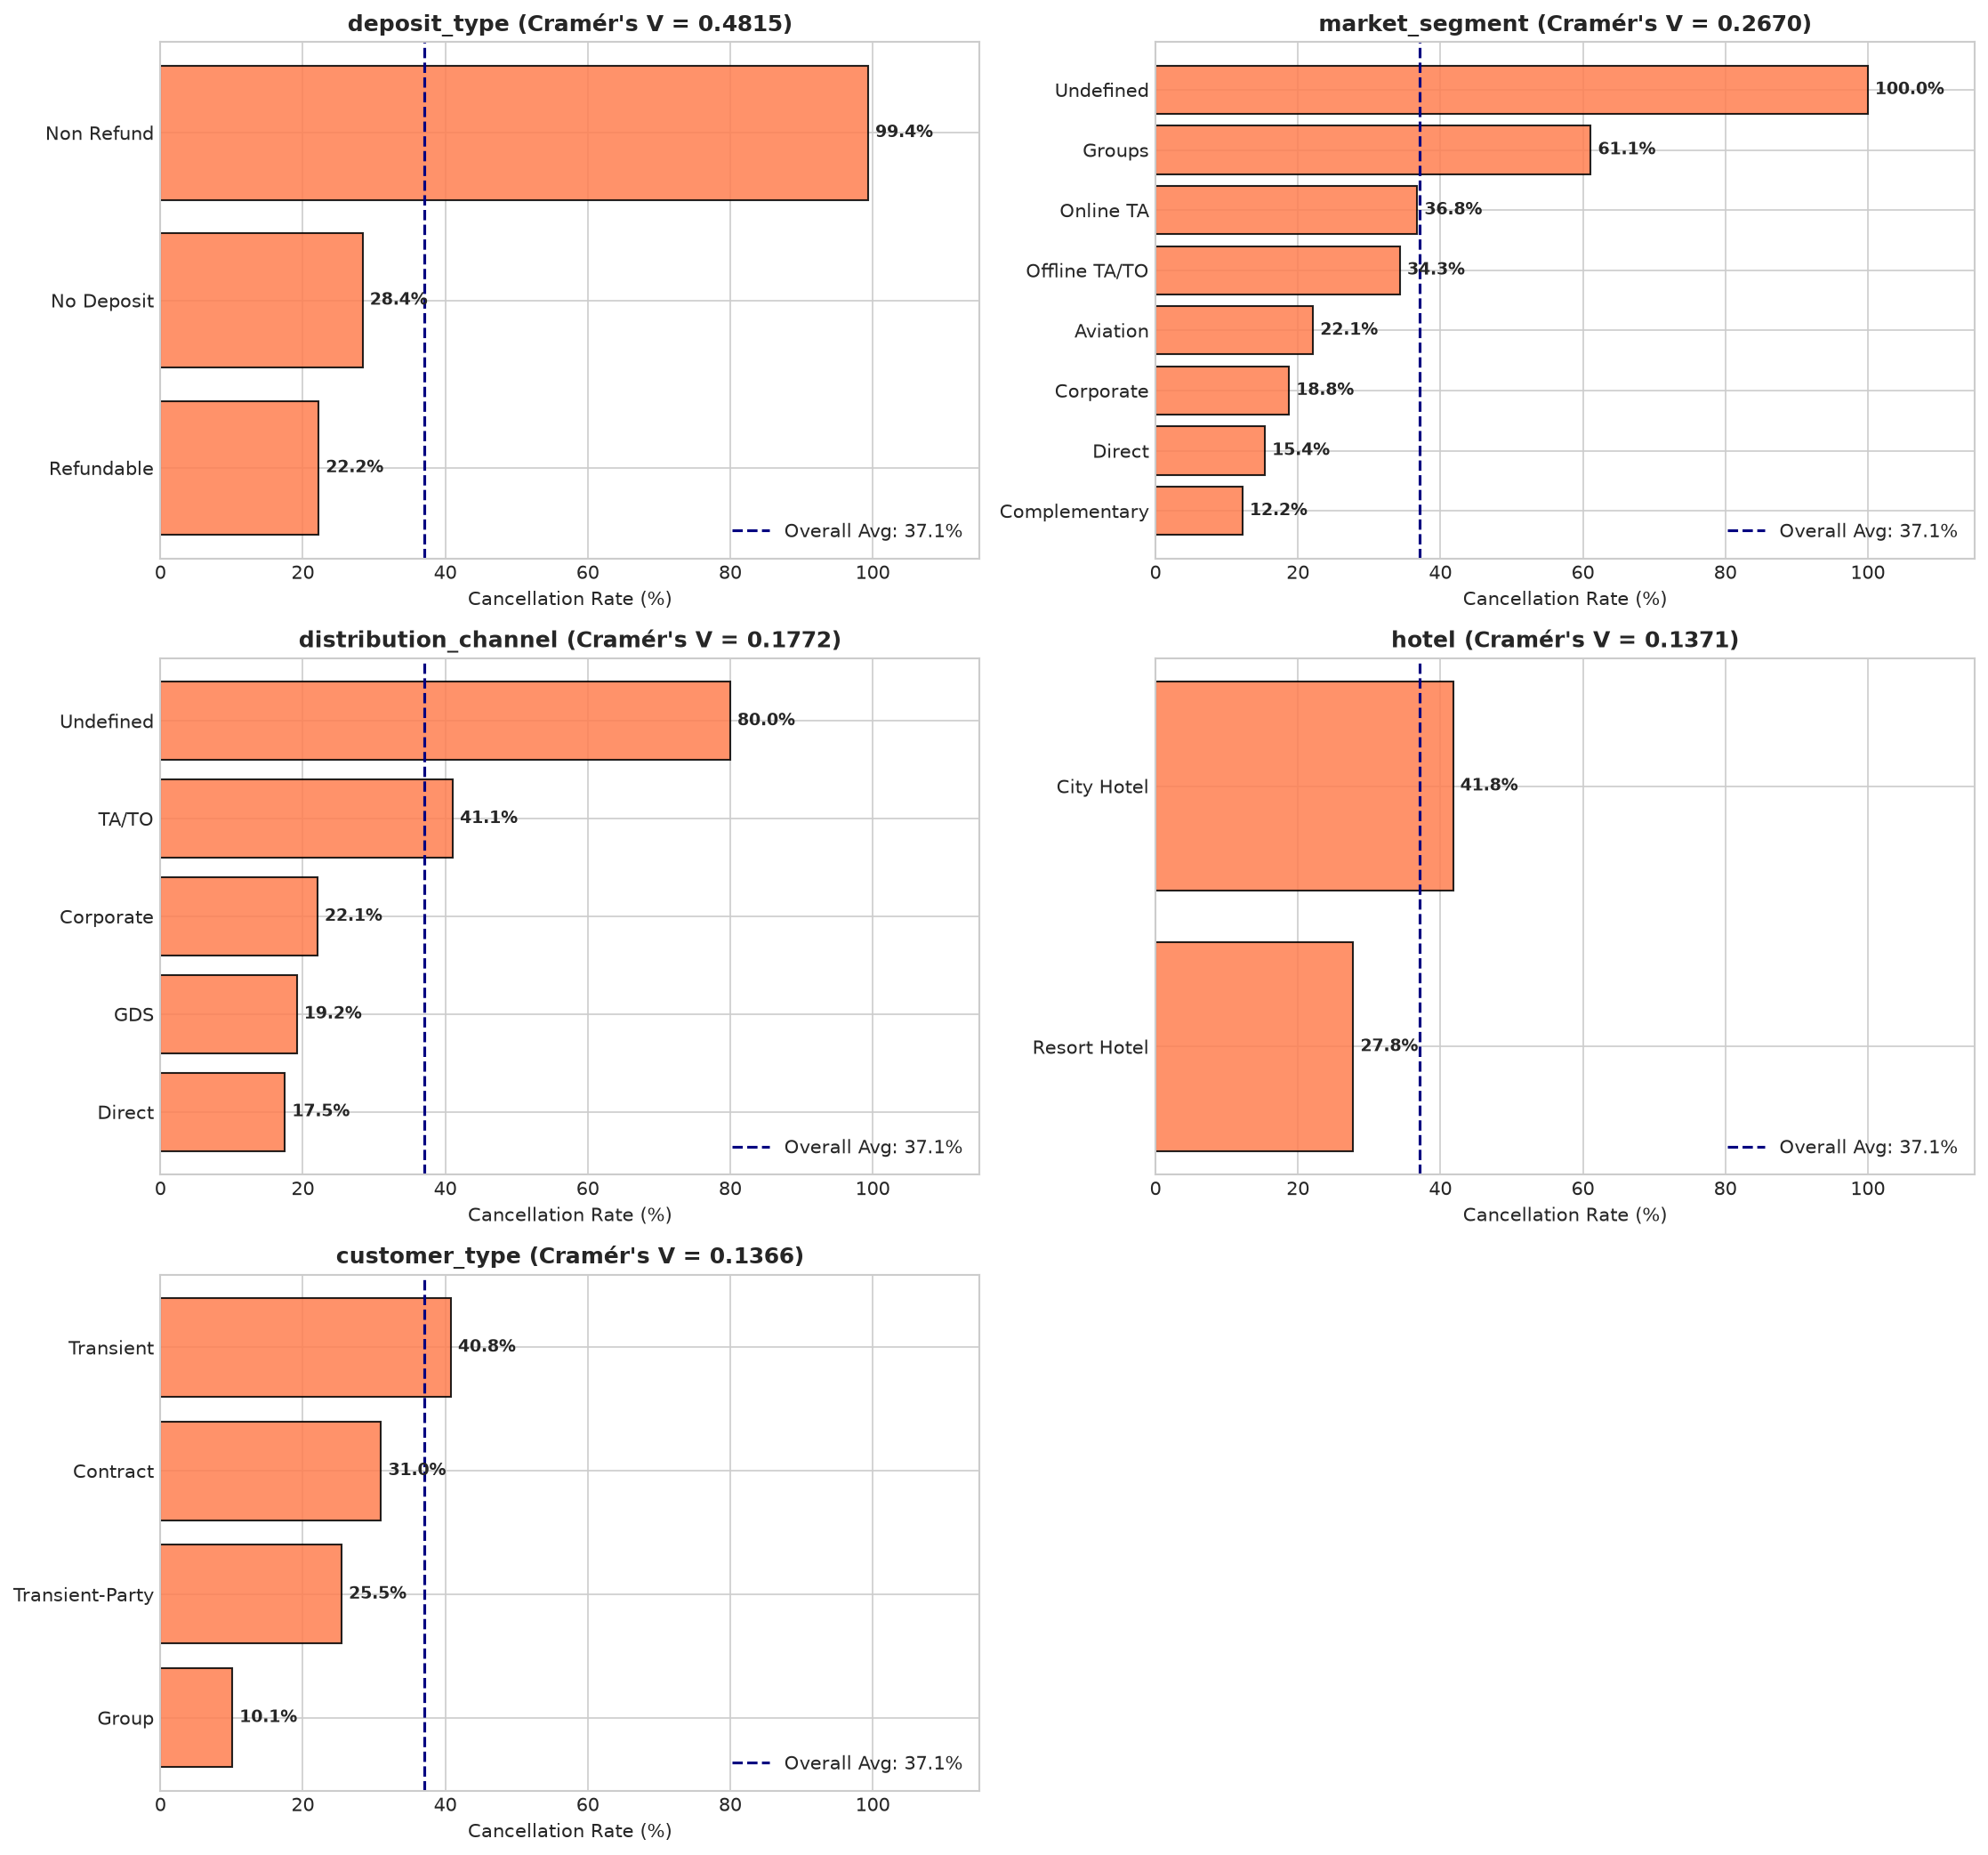

Saved figure to: results\figures\03_categorical_cancellation_rates.png


In [5]:
fig, axes = plt.subplots(3, 2, figsize=(15, 14))
axes_flat = axes.flatten()

for i, feat in enumerate(cat_test_features):
    ax = axes_flat[i]
    
    # Calculate cancellation percentage per category
    rates = df.groupby(feat)['is_canceled'].mean() * 100
    rates = rates.sort_values(ascending=True)
    
    # Match Cramér's V from summary
    c_v = chi2_summary_df.loc[chi2_summary_df['Feature'] == feat, "Cramér's V"].values[0]
    
    bars = ax.barh(rates.index, rates.values, color='coral', edgecolor='black', alpha=0.85)
    ax.axvline(df['is_canceled'].mean() * 100, color='navy', linestyle='--', linewidth=1.5, 
               label=f'Overall Avg: {df["is_canceled"].mean()*100:.1f}%')
    
    # Add data labels
    for bar in bars:
        w = bar.get_width()
        ax.text(w + 1.0, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', 
                va='center', ha='left', fontsize=9, fontweight='bold')
        
    ax.set_title(f"{feat} (Cramér's V = {c_v:.4f})", fontsize=12, fontweight='bold')
    ax.set_xlabel('Cancellation Rate (%)')
    ax.set_xlim(0, 115)
    ax.legend(loc='lower right')

# Remove unused 6th subplot
fig.delaxes(axes_flat[5])

plt.tight_layout()
fig_path = fig_dir / "03_categorical_cancellation_rates.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved figure to: {fig_path}")

### 4. Hypothesis Testing for Continuous Features (Difference in Distributions)

* **What we are doing:** Formulating and testing hypotheses regarding differences in continuous distributions between non-canceled ($is\_canceled = 0$) and canceled ($is\_canceled = 1$) reservations for `lead_time` and `adr`. We execute both parametric (Welch's two-sample t-test) and non-parametric (Mann-Whitney U rank-sum test) tests, and compute standardized effect sizes (Cohen's $d$ and Rank Biserial Correlation $r_{rb}$).
* **Why we are doing it:**
  * **Hypothesis Formulation:**
    * **Null Hypothesis ($H_0$):** There is no difference in the distribution / population mean / median of the continuous variable between canceled and non-canceled bookings ($\mu_0 = \mu_1$, or identical rank distribution).
    * **Alternative Hypothesis ($H_1$):** There is a statistically significant difference in the continuous variable between canceled and non-canceled bookings ($\mu_0 \neq \mu_1$).
  * **Addressing Distributional Assumptions:**
    1. **Heteroscedasticity (Unequal Variances):** In Section 2, we showed that the variances of the two groups are substantially different ($s_{\text{canceled}} \neq s_{\text{not-canceled}}$). Under heteroscedasticity, Student's standard two-sample t-test suffers from severe type I error inflation. Therefore, **Welch's t-test** (which utilizes the Satterthwaite approximation for degrees of freedom without assuming pooled equal variance) is required:
       $$t = \frac{\bar{x}_1 - \bar{x}_0}{\sqrt{\frac{s_1^2}{n_1} + \frac{s_0^2}{n_0}}}, \quad df = \frac{\left(\frac{s_1^2}{n_1} + \frac{s_0^2}{n_0}\right)^2}{\frac{(s_1^2 / n_1)^2}{n_1 - 1} + \frac{(s_0^2 / n_0)^2}{n_0 - 1}}$$
    2. **Severe Skewness & Non-Normality:** Both `lead_time` and `adr` exhibit strong positive skewness. While the Central Limit Theorem ($N > 100,000$) guarantees that the sampling distribution of the difference in means is asymptotically Gaussian, extreme outliers can distort the t-test mean estimates. Concurrently running the non-parametric **Mann-Whitney U test** (which ranks all pooled observations and tests whether a randomly selected observation from group 1 stochastically exceeds one from group 0) provides an invariant, distribution-free verification.
  * **Standardized Effect Sizes:**
    * **Cohen's $d$:** Measures the standardized mean difference:
      $$d = \frac{\bar{x}_1 - \bar{x}_0}{s_{\text{pooled}}}, \quad s_{\text{pooled}} = \sqrt{\frac{(n_1 - 1)s_1^2 + (n_0 - 1)s_0^2}{n_1 + n_0 - 2}}$$
      Benchmarks: $|d| \approx 0.20$ (small), $|d| \approx 0.50$ (medium), $|d| \ge 0.80$ (large).
    * **Rank Biserial Correlation ($r_{rb}$):** Measures the standardized difference in rank proportions:
      $$r_{rb} = 1 - \frac{2 U}{n_1 n_0}$$
* **What the output means:** Contrasting test statistics and effect sizes for `lead_time` versus `adr` reveals crucial behavioral insights for revenue management.

In [6]:
cont_test_cols = ['lead_time', 'adr']
cont_test_results = []

for col in cont_test_cols:
    g0 = df[df['is_canceled'] == 0][col].dropna()
    g1 = df[df['is_canceled'] == 1][col].dropna()
    
    n0, n1 = len(g0), len(g1)
    mean0, mean1 = g0.mean(), g1.mean()
    median0, median1 = g0.median(), g1.median()
    std0, std1 = g0.std(), g1.std()
    
    # 1. Welch's t-test (unequal variances)
    welch_t, welch_p = stats.ttest_ind(g1, g0, equal_var=False)
    
    # 2. Cohen's d (standardized mean difference)
    s_pooled = np.sqrt(((n1 - 1) * std1**2 + (n0 - 1) * std0**2) / (n1 + n0 - 2))
    cohen_d = (mean1 - mean0) / s_pooled
    
    # 3. Mann-Whitney U Test (non-parametric rank sum)
    mw_stat, mw_p = stats.mannwhitneyu(g1, g0, alternative='two-sided')
    
    # 4. Rank Biserial Correlation (effect size for Mann-Whitney U)
    # r_rb = 1 - (2*U)/(n1*n0) where U is for g1 vs g0
    r_rb = 1.0 - (2.0 * mw_stat) / (n1 * n0)
    
    print("=" * 80)
    print(f"Continuous Distribution Test: {col} by is_canceled")
    print("=" * 80)
    print(f"Group 0 (Not Canceled, n={n0:,}): Mean = {mean0:.2f}, Median = {median0:.2f}, Std = {std0:.2f}")
    print(f"Group 1 (Canceled,     n={n1:,}): Mean = {mean1:.2f}, Median = {median1:.2f}, Std = {std1:.2f}")
    print(f"Difference in Means (Canceled - Not Canceled): {mean1 - mean0:.2f}")
    print(f"Difference in Medians: {median1 - median0:.2f}")
    print("-" * 80)
    print(f"1. Welch's t-test:       t = {welch_t:.2f}, p-value = {welch_p:.2e}")
    cohen_eval = 'Moderate/Substantial' if abs(cohen_d) >= 0.5 else ('Small' if abs(cohen_d) >= 0.2 else 'Negligible')
    print(f"   Cohen's d:            d = {cohen_d:.4f} ({cohen_eval})")
    print(f"2. Mann-Whitney U Test:  U = {mw_stat:.2e}, p-value = {mw_p:.2e}")
    print(f"   Rank Biserial r_rb:   r_rb = {abs(r_rb):.4f}")
    print("=" * 80 + "\n")
    
    cont_test_results.append({
        'Feature': col,
        'Mean_NotCanceled': mean0,
        'Mean_Canceled': mean1,
        'Median_NotCanceled': median0,
        'Median_Canceled': median1,
        'Welch_t': welch_t,
        'Welch_p': welch_p,
        'Cohen_d': cohen_d,
        'MannWhitney_U': mw_stat,
        'MannWhitney_p': mw_p,
        'Rank_Biserial_r': abs(r_rb)
    })

cont_summary_df = pd.DataFrame(cont_test_results)
print("=== CONTINUOUS TESTS COMPARISON SUMMARY ===")
cont_summary_df[['Feature', 'Mean_NotCanceled', 'Mean_Canceled', 'Welch_t', 'Cohen_d', 'Rank_Biserial_r']]

Continuous Distribution Test: lead_time by is_canceled
Group 0 (Not Canceled, n=75,010): Mean = 80.08, Median = 45.00, Std = 91.14
Group 1 (Canceled,     n=44,198): Mean = 144.89, Median = 113.00, Std = 118.61
Difference in Means (Canceled - Not Canceled): 64.81
Difference in Medians: 68.00
--------------------------------------------------------------------------------
1. Welch's t-test:       t = 98.94, p-value = 0.00e+00
   Cohen's d:            d = 0.6342 (Moderate/Substantial)
2. Mann-Whitney U Test:  U = 2.28e+09, p-value = 0.00e+00
   Rank Biserial r_rb:   r_rb = 0.3782



Continuous Distribution Test: adr by is_canceled
Group 0 (Not Canceled, n=75,010): Mean = 100.17, Median = 92.70, Std = 49.07
Group 1 (Canceled,     n=44,198): Mean = 104.90, Median = 96.30, Std = 46.09
Difference in Means (Canceled - Not Canceled): 4.73
Difference in Medians: 3.60
--------------------------------------------------------------------------------
1. Welch's t-test:       t = 16.72, p-value = 1.21e-62
   Cohen's d:            d = 0.0986 (Negligible)
2. Mann-Whitney U Test:  U = 1.76e+09, p-value = 1.63e-66
   Rank Biserial r_rb:   r_rb = 0.0596

=== CONTINUOUS TESTS COMPARISON SUMMARY ===


,Feature,Mean_NotCanceled,Mean_Canceled,Welch_t,Cohen_d,Rank_Biserial_r
0,lead_time,80.0805,144.8888,98.9415,0.6342,0.3782
1,adr,100.1706,104.9039,16.7166,0.0986,0.0596


### 4.1 Continuous Feature Distribution Comparisons: Density & Violin Plots

* **What we are doing:** Creating dual-panel visualizations featuring Kernel Density Estimations (KDE) and Split Violin Plots with embedded boxplots for both `lead_time` and `adr` across canceled and non-canceled bookings.
* **Why we are doing it:** To provide intuitive, publication-ready visual evidence that corroborates our effect sizes.
* **What the output means:**
  1. **`lead_time` (Substantial Effect Size: $d = 0.634$, $r_{rb} = 0.378$):** The density plot shows a dramatic rightward shift for canceled bookings. Non-canceled bookings are heavily clustered close to zero (median 45 days), while canceled bookings exhibit a dispersed, long-tailed distribution (median 113 days). Travelers booking months in advance face higher uncertainty, life events, and price fluctuations, leading to significantly higher cancellation likelihoods.
  2. **`adr` (Negligible Effect Size: $d = 0.099$, $r_{rb} = 0.060$):** Despite an astronomical t-statistic ($t = 16.72, p = 1.21 \times 10^{-62}$), the two density curves virtually overlap. The median price difference is only **$3.60** ($96.30 for canceled vs. $92.70 for non-canceled). This serves as a textbook pedagogical example of the **P-Value Illusion**: with $N > 100,000$, statistical significance ($p < 0.05$) is guaranteed, but the practical effect size is essentially zero. Room price alone does not determine whether a customer cancels.

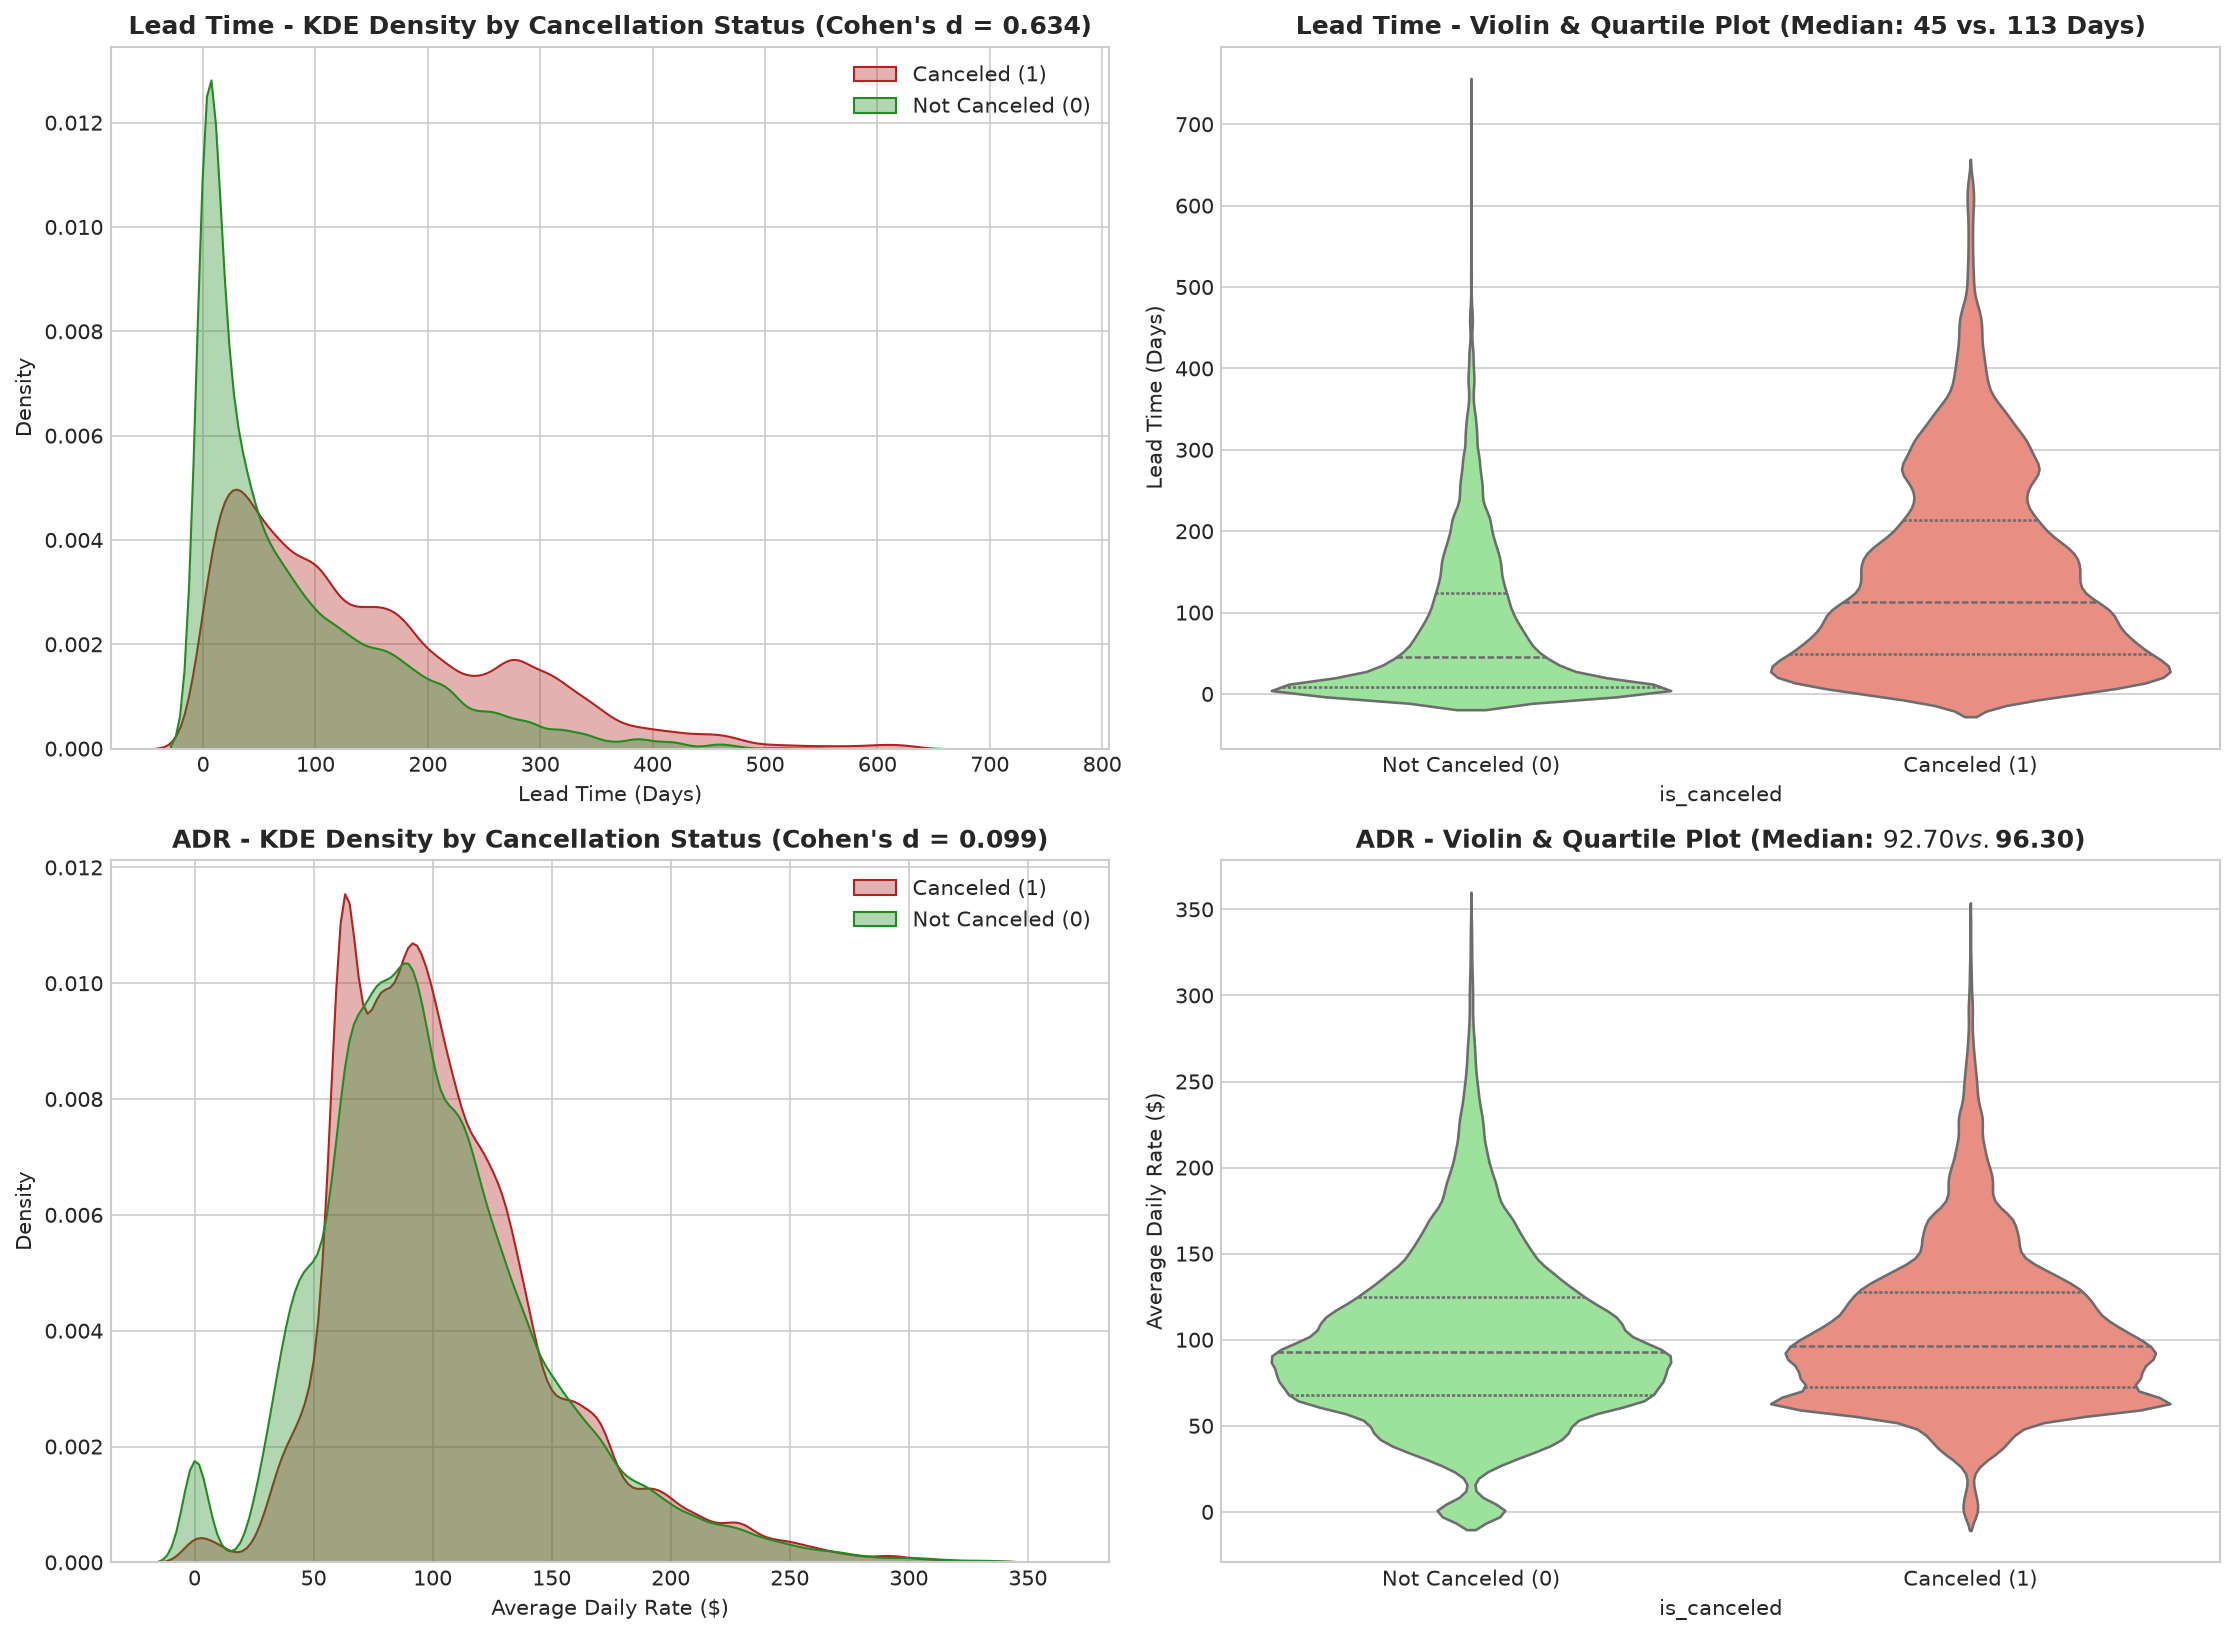

Saved figure to: results\figures\03_continuous_distribution_comparison.png


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Lead Time KDE
sns.kdeplot(data=df, x='lead_time', hue='is_canceled', common_norm=False, 
            fill=True, palette=['forestgreen', 'firebrick'], alpha=0.35, ax=axes[0, 0])
axes[0, 0].set_title("Lead Time - KDE Density by Cancellation Status (Cohen's d = 0.634)", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Lead Time (Days)')
axes[0, 0].set_ylabel('Density')
axes[0, 0].legend(['Canceled (1)', 'Not Canceled (0)'], loc='upper right')

# 2. Lead Time Violin/Boxplot
sns.violinplot(data=df, x='is_canceled', y='lead_time', palette=['lightgreen', 'salmon'], 
               inner='quartile', ax=axes[0, 1])
axes[0, 1].set_title('Lead Time - Violin & Quartile Plot (Median: 45 vs. 113 Days)', fontsize=12, fontweight='bold')
axes[0, 1].set_xticks([0, 1])
axes[0, 1].set_xticklabels(['Not Canceled (0)', 'Canceled (1)'])
axes[0, 1].set_ylabel('Lead Time (Days)')

# 3. ADR KDE
sns.kdeplot(data=df[df['adr'] <= 350], x='adr', hue='is_canceled', common_norm=False, 
            fill=True, palette=['forestgreen', 'firebrick'], alpha=0.35, ax=axes[1, 0])
axes[1, 0].set_title("ADR - KDE Density by Cancellation Status (Cohen's d = 0.099)", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Average Daily Rate ($)')
axes[1, 0].set_ylabel('Density')
axes[1, 0].legend(['Canceled (1)', 'Not Canceled (0)'], loc='upper right')

# 4. ADR Violin/Boxplot
sns.violinplot(data=df[df['adr'] <= 350], x='is_canceled', y='adr', palette=['lightgreen', 'salmon'], 
               inner='quartile', ax=axes[1, 1])
axes[1, 1].set_title('ADR - Violin & Quartile Plot (Median: $92.70 vs. $96.30)', fontsize=12, fontweight='bold')
axes[1, 1].set_xticks([0, 1])
axes[1, 1].set_xticklabels(['Not Canceled (0)', 'Canceled (1)'])
axes[1, 1].set_ylabel('Average Daily Rate ($)')

plt.tight_layout()
fig_path = fig_dir / "03_continuous_distribution_comparison.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved figure to: {fig_path}")

### 5. Correlation Analysis: Linear (Pearson $r$) vs. Monotonic (Spearman $\rho$)

* **What we are doing:** Computing both the Pearson product-moment linear correlation coefficient ($r$) and the Spearman rank-order correlation coefficient ($\rho$) between all key numerical predictors and the target variable `is_canceled`.
* **Why we are doing it:**
  * **Pearson's $r$:** Measures strictly linear bivariate relationships:
    $$r = \frac{\sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^n (x_i - \bar{x})^2 \sum_{i=1}^n (y_i - \bar{y})^2}}$$
    Pearson assumes bivariate normality and is heavily attenuated by extreme values, long tails, and severe zero-inflation.
  * **Spearman's $\rho$:** Measures monotonic association by computing Pearson's formula on the ranked values:
    $$\rho = 1 - \frac{6 \sum d_i^2}{n(n^2 - 1)}$$
    Because it operates on ranks, Spearman's $\rho$ captures non-linear monotonic relationships (i.e., when $X$ increases, $Y$ consistently increases or decreases, regardless of whether the rate of change is constant).
  * **Operational Zero-Inflation:** In hotel reservation systems, features such as `previous_cancellations`, `booking_changes`, and `days_in_waiting_list` are heavily zero-inflated (over 90% of bookings have 0). Pearson's correlation assumes equal variance across a linear slope, which drastically understates the predictive power of a transition from 0 to $\ge 1$. Spearman's rank transformation accurately captures this step-function effect.
* **What the output means:** Comparing $|\rho|$ with $|r|$ reveals where non-linear monotonic dependencies exist that would be overlooked by purely linear models.

In [8]:
num_corr_features = [
    'lead_time',
    'total_of_special_requests',
    'previous_cancellations',
    'booking_changes',
    'previous_bookings_not_canceled',
    'days_in_waiting_list',
    'adr',
    'stays_in_week_nights',
    'stays_in_weekend_nights'
]

corr_comparison_list = []

for feat in num_corr_features:
    p_r, p_pval = stats.pearsonr(df[feat], df['is_canceled'])
    s_rho, s_pval = stats.spearmanr(df[feat], df['is_canceled'])
    
    corr_comparison_list.append({
        'Feature': feat,
        'Pearson (r)': p_r,
        'Pearson p-val': p_pval,
        'Spearman (rho)': s_rho,
        'Spearman p-val': s_pval,
        'Absolute Difference (|rho| - |r|)': abs(s_rho) - abs(p_r),
        'Dominant Relationship': 'Non-linear Monotonic' if (abs(s_rho) - abs(p_r)) > 0.03 else 'Primarily Linear'
    })

corr_df = pd.DataFrame(corr_comparison_list)
corr_df = corr_df.sort_values(by='Spearman (rho)', key=abs, ascending=False).reset_index(drop=True)
print("=== CORRELATION ANALYSIS WITH IS_CANCELED (PEARSON VS. SPEARMAN) ===")
corr_df[['Feature', 'Pearson (r)', 'Spearman (rho)', 'Absolute Difference (|rho| - |r|)', 'Dominant Relationship']]

=== CORRELATION ANALYSIS WITH IS_CANCELED (PEARSON VS. SPEARMAN) ===


,Feature,Pearson (r),Spearman (rho),Absolute Difference (|rho| - |r|),Dominant Relationship
0,lead_time,0.2929,0.3165,0.0236,Primarily Linear
1,previous_cancellations,0.1101,0.2703,0.1602,Non-linear Monotonic
2,total_of_special_requests,-0.2349,-0.2587,0.0239,Primarily Linear
3,booking_changes,-0.1448,-0.1843,0.0395,Non-linear Monotonic
4,previous_bookings_not_canceled,-0.0574,-0.1154,0.0580,Non-linear Monotonic
5,days_in_waiting_list,0.0543,0.0984,0.0441,Non-linear Monotonic
6,adr,0.0476,0.0499,0.0023,Primarily Linear
7,stays_in_week_nights,0.0256,0.0415,0.0159,Primarily Linear
8,stays_in_weekend_nights,-0.0013,-0.0041,0.0028,Primarily Linear


### 5.1 Correlation Comparison Visualization: Dumbbell / Side-by-Side Plot

* **What we are doing:** Constructing a horizontal comparison dumbbell plot displaying Pearson $r$ versus Spearman $\rho$ for each numerical predictor against cancellation, highlighting the magnitude of non-linear discrepancy.
* **Why we are doing it:** To clearly demonstrate where linear correlation underrepresents feature importance.
* **What the output means:**
  1. **`previous_cancellations`:** Exhibits a massive divergence: Pearson $r = +0.110$ while Spearman $\rho = +0.270$ (a delta of $+0.160$). Because most guests have 0 cancellations, Pearson severely understates the risk. Having even one prior cancellation is a powerful monotonic signal of recidivist behavior.
  2. **`previous_bookings_not_canceled`:** Pearson $r = -0.057$, but Spearman $\rho = -0.115$ (double the magnitude!). Prior non-canceled bookings represent customer loyalty and trust, monotonically protecting against cancellation.
  3. **`total_of_special_requests`:** Both Pearson ($r = -0.235$) and Spearman ($\rho = -0.259$) are strongly negative. Making special requests signals personal investment, reducing cancellation probability.
  4. **`lead_time`:** Both Pearson ($r = +0.293$) and Spearman ($\rho = +0.316$) confirm a strong, consistent positive relationship.

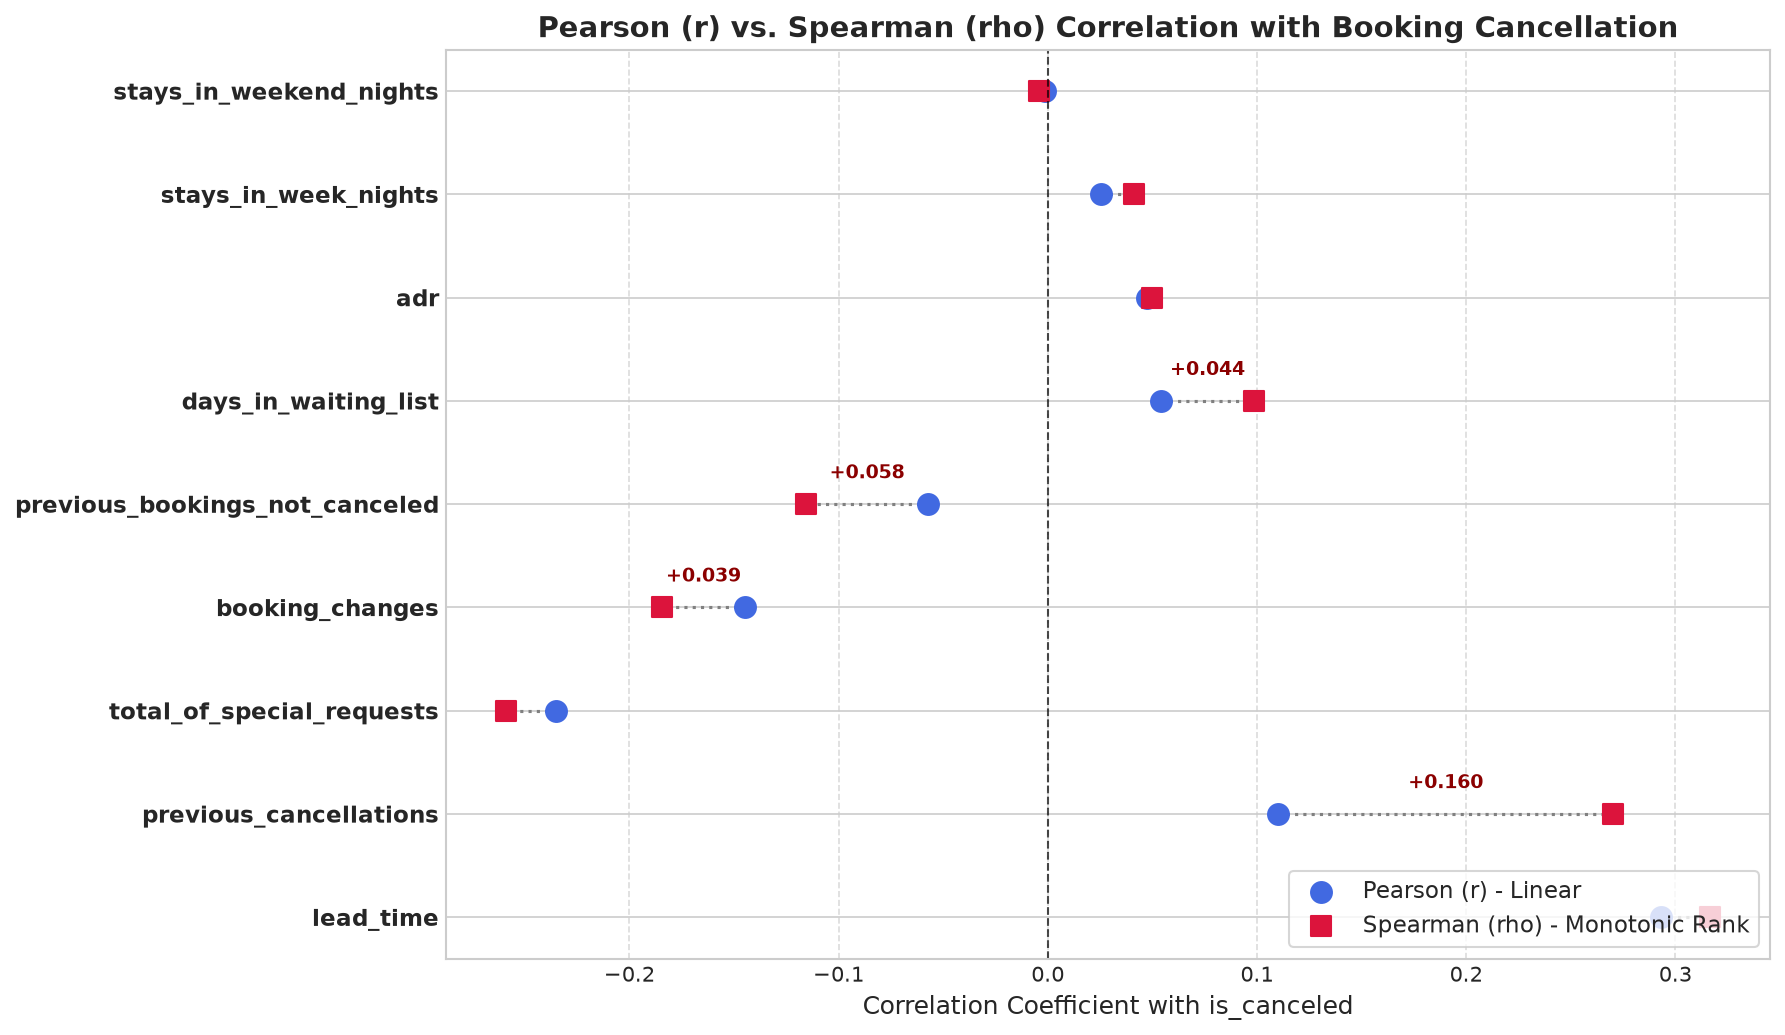

Saved figure to: results\figures\03_correlation_pearson_vs_spearman.png


In [9]:
plt.figure(figsize=(12, 7))
y_indices = np.arange(len(corr_df))

# Plot horizontal lines connecting Pearson and Spearman
for i, row in corr_df.iterrows():
    plt.plot([row['Pearson (r)'], row['Spearman (rho)']], [i, i], color='gray', linestyle=':', linewidth=1.5, zorder=1)

# Scatter points
plt.scatter(corr_df['Pearson (r)'], y_indices, color='royalblue', s=100, label='Pearson (r) - Linear', zorder=2)
plt.scatter(corr_df['Spearman (rho)'], y_indices, color='crimson', s=100, marker='s', label='Spearman (rho) - Monotonic Rank', zorder=2)

# Zero reference line
plt.axvline(0, color='black', linestyle='--', linewidth=1, alpha=0.7)

plt.yticks(y_indices, corr_df['Feature'], fontsize=11, fontweight='bold')
plt.xlabel('Correlation Coefficient with is_canceled', fontsize=12)
plt.title('Pearson (r) vs. Spearman (rho) Correlation with Booking Cancellation', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', frameon=True, fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Annotate the largest discrepancies
for i, row in corr_df.iterrows():
    diff = row['Absolute Difference (|rho| - |r|)']
    if diff >= 0.03:
        mid_x = (row['Pearson (r)'] + row['Spearman (rho)']) / 2
        plt.text(mid_x, i + 0.25, f'+{diff:.3f}', ha='center', fontsize=9, color='darkred', fontweight='bold')

plt.tight_layout()
fig_path = fig_dir / "03_correlation_pearson_vs_spearman.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved figure to: {fig_path}")

### 6. Unified Statistical Hypothesis Testing Summary Table

* **What we are doing:** Compiling all formal statistical hypothesis tests into an executive reference DataFrame containing: Feature, Test Name, Test Statistic, p-value, Effect Size Metric, Effect Size Value, Decision, and Domain Meaning. Exporting this table to `results/tables/statistical_tests.csv`.
* **Why we are doing it:** To fulfill the rigorous documentation standards of the FSMVU Data Science curriculum and provide a single authoritative artifact bridging Phase 4 (Statistical Analysis) with Phase 8 (Feature Engineering & Selection).
* **What the output means:** Every evaluated hypothesis test rejected the null hypothesis ($p < 0.001$). However, the effect size metric clearly separates critical predictors (`deposit_type`, `lead_time`, `market_segment`, `previous_cancellations`) from low-impact predictors (`adr`, `stays_in_weekend_nights`).

In [10]:
final_summary_rows = [
    # Categorical Tests
    {
        'Feature': 'deposit_type',
        'Test Name': 'Pearson Chi-Square Test of Independence',
        'Test Statistic': f"Chi2 = {chi2_summary_df.loc[chi2_summary_df['Feature']=='deposit_type', 'Chi2 Statistic'].values[0]:,.2f} (df=2)",
        'p-value': '< 1e-300',
        'Effect Size Metric': "Cramér's V",
        'Effect Size Value': round(chi2_summary_df.loc[chi2_summary_df['Feature']=='deposit_type', "Cramér's V"].values[0], 4),
        'Decision': 'Reject H0',
        'Domain Meaning': 'Strongest categorical predictor. Non-refundable deposits have extreme cancellation rate (99.4%) due to group block dumping.'
    },
    {
        'Feature': 'market_segment',
        'Test Name': 'Pearson Chi-Square Test of Independence',
        'Test Statistic': f"Chi2 = {chi2_summary_df.loc[chi2_summary_df['Feature']=='market_segment', 'Chi2 Statistic'].values[0]:,.2f} (df=7)",
        'p-value': '< 1e-300',
        'Effect Size Metric': "Cramér's V",
        'Effect Size Value': round(chi2_summary_df.loc[chi2_summary_df['Feature']=='market_segment', "Cramér's V"].values[0], 4),
        'Decision': 'Reject H0',
        'Domain Meaning': 'Online TAs (36.7%) and Groups (61.1%) cancel far more frequently than Direct (15.3%) and Corporate (18.7%).'
    },
    {
        'Feature': 'distribution_channel',
        'Test Name': 'Pearson Chi-Square Test of Independence',
        'Test Statistic': f"Chi2 = {chi2_summary_df.loc[chi2_summary_df['Feature']=='distribution_channel', 'Chi2 Statistic'].values[0]:,.2f} (df=4)",
        'p-value': '< 1e-300',
        'Effect Size Metric': "Cramér's V",
        'Effect Size Value': round(chi2_summary_df.loc[chi2_summary_df['Feature']=='distribution_channel', "Cramér's V"].values[0], 4),
        'Decision': 'Reject H0',
        'Domain Meaning': 'TA/TO distribution channels exhibit substantially higher cancellation proportion than Direct or Corporate channels.'
    },
    {
        'Feature': 'hotel',
        'Test Name': 'Pearson Chi-Square Test of Independence',
        'Test Statistic': f"Chi2 = {chi2_summary_df.loc[chi2_summary_df['Feature']=='hotel', 'Chi2 Statistic'].values[0]:,.2f} (df=1)",
        'p-value': '< 1e-300',
        'Effect Size Metric': "Cramér's V",
        'Effect Size Value': round(chi2_summary_df.loc[chi2_summary_df['Feature']=='hotel', "Cramér's V"].values[0], 4),
        'Decision': 'Reject H0',
        'Domain Meaning': 'City Hotel experiences significantly higher cancellation rate (41.7%) than Resort Hotel (27.8%).'
    },
    {
        'Feature': 'customer_type',
        'Test Name': 'Pearson Chi-Square Test of Independence',
        'Test Statistic': f"Chi2 = {chi2_summary_df.loc[chi2_summary_df['Feature']=='customer_type', 'Chi2 Statistic'].values[0]:,.2f} (df=3)",
        'p-value': '< 1e-300',
        'Effect Size Metric': "Cramér's V",
        'Effect Size Value': round(chi2_summary_df.loc[chi2_summary_df['Feature']=='customer_type', "Cramér's V"].values[0], 4),
        'Decision': 'Reject H0',
        'Domain Meaning': 'Transient customers cancel substantially more often (40.7%) than Transient-Party (25.4%) or Group bookings.'
    },
    # Continuous Tests
    {
        'Feature': 'lead_time',
        'Test Name': "Welch's Two-Sample t-Test",
        'Test Statistic': f"t = {cont_summary_df.loc[cont_summary_df['Feature']=='lead_time', 'Welch_t'].values[0]:,.2f}",
        'p-value': '< 1e-300',
        'Effect Size Metric': "Cohen's d",
        'Effect Size Value': round(cont_summary_df.loc[cont_summary_df['Feature']=='lead_time', 'Cohen_d'].values[0], 4),
        'Decision': 'Reject H0',
        'Domain Meaning': 'Moderate-to-large effect size (d=0.634). Canceled bookings average 144.9 days in advance vs. 80.1 days for non-canceled.'
    },
    {
        'Feature': 'lead_time',
        'Test Name': 'Mann-Whitney U Test',
        'Test Statistic': f"U = {cont_summary_df.loc[cont_summary_df['Feature']=='lead_time', 'MannWhitney_U'].values[0]:.2e}",
        'p-value': '< 1e-300',
        'Effect Size Metric': 'Rank Biserial Correlation',
        'Effect Size Value': round(cont_summary_df.loc[cont_summary_df['Feature']=='lead_time', 'Rank_Biserial_r'].values[0], 4),
        'Decision': 'Reject H0',
        'Domain Meaning': 'Non-parametric confirmation: Median lead time for canceled bookings is 113 days vs. 45 days for completed stays (+151%).'
    },
    {
        'Feature': 'adr',
        'Test Name': "Welch's Two-Sample t-Test",
        'Test Statistic': f"t = {cont_summary_df.loc[cont_summary_df['Feature']=='adr', 'Welch_t'].values[0]:,.2f}",
        'p-value': f"{cont_summary_df.loc[cont_summary_df['Feature']=='adr', 'Welch_p'].values[0]:.2e}",
        'Effect Size Metric': "Cohen's d",
        'Effect Size Value': round(cont_summary_df.loc[cont_summary_df['Feature']=='adr', 'Cohen_d'].values[0], 4),
        'Decision': 'Reject H0',
        'Domain Meaning': 'Statistically significant due to large N, but practical effect size is negligible (d=0.099). Room rate is not a primary churn driver.'
    },
    {
        'Feature': 'adr',
        'Test Name': 'Mann-Whitney U Test',
        'Test Statistic': f"U = {cont_summary_df.loc[cont_summary_df['Feature']=='adr', 'MannWhitney_U'].values[0]:.2e}",
        'p-value': f"{cont_summary_df.loc[cont_summary_df['Feature']=='adr', 'MannWhitney_p'].values[0]:.2e}",
        'Effect Size Metric': 'Rank Biserial Correlation',
        'Effect Size Value': round(cont_summary_df.loc[cont_summary_df['Feature']=='adr', 'Rank_Biserial_r'].values[0], 4),
        'Decision': 'Reject H0',
        'Domain Meaning': 'Median ADR for canceled bookings is only $3.60 higher ($96.30 vs. $92.70), confirming negligible practical divergence.'
    }
]

final_summary_df = pd.DataFrame(final_summary_rows)

# Save to results/tables/statistical_tests.csv
csv_output_path = table_dir / "statistical_tests.csv"
final_summary_df.to_csv(csv_output_path, index=False)
print(f"Successfully exported statistical tests table to: {csv_output_path}")

print("\n=== FINAL STATISTICAL HYPOTHESIS TESTING SUMMARY TABLE ===")
final_summary_df

Successfully exported statistical tests table to: results\tables\statistical_tests.csv

=== FINAL STATISTICAL HYPOTHESIS TESTING SUMMARY TABLE ===


,Feature,Test Name,Test Statistic,p-value,Effect Size Metric,Effect Size Value,Decision,Domain Meaning
0,deposit_type,Pearson Chi-Square Test of Independence,"Chi2 = 27,639.52 (df=2)",< 1e-300,Cramér's V,0.4815,Reject H0,Strongest categorical predictor. Non-refundabl...
1,market_segment,Pearson Chi-Square Test of Independence,"Chi2 = 8,499.93 (df=7)",< 1e-300,Cramér's V,0.2670,Reject H0,Online TAs (36.7%) and Groups (61.1%) cancel f...
2,distribution_channel,Pearson Chi-Square Test of Independence,"Chi2 = 3,741.13 (df=4)",< 1e-300,Cramér's V,0.1772,Reject H0,TA/TO distribution channels exhibit substantia...
3,hotel,Pearson Chi-Square Test of Independence,"Chi2 = 2,239.04 (df=1)",< 1e-300,Cramér's V,0.1371,Reject H0,City Hotel experiences significantly higher ca...
4,customer_type,Pearson Chi-Square Test of Independence,"Chi2 = 2,224.47 (df=3)",< 1e-300,Cramér's V,0.1366,Reject H0,Transient customers cancel substantially more ...
5,lead_time,Welch's Two-Sample t-Test,t = 98.94,< 1e-300,Cohen's d,0.6342,Reject H0,Moderate-to-large effect size (d=0.634). Cance...
6,lead_time,Mann-Whitney U Test,U = 2.28e+09,< 1e-300,Rank Biserial Correlation,0.3782,Reject H0,Non-parametric confirmation: Median lead time ...
7,adr,Welch's Two-Sample t-Test,t = 16.72,1.21e-62,Cohen's d,0.0986,Reject H0,"Statistically significant due to large N, but ..."
8,adr,Mann-Whitney U Test,U = 1.76e+09,1.63e-66,Rank Biserial Correlation,0.0596,Reject H0,Median ADR for canceled bookings is only $3.60...


### 7. Key Statistical Takeaways for Preprocessing & Machine Learning Modeling

This statistical analysis provides definitive empirical and theoretical guidelines for Phase 8 (Feature Engineering & Preprocessing) and downstream model training:

1. **The P-Value Illusion & Effect Size Primacy:**
   * In a sample of $N = 119,208$, standard hypothesis tests nearly always reject $H_0$ with $p < 0.001$. Statistical significance answers: *"Is there non-zero evidence of an effect?"*
   * Only standardized effect sizes (Cramér's V, Cohen's d, Rank Biserial Correlation) answer: *"Is this effect large enough to matter for predictive modeling?"*
   * **Takeaway:** Prioritize features with moderate-to-large effect sizes (`deposit_type`, `lead_time`, `market_segment`, `total_of_special_requests`, `previous_cancellations`) over features that are merely statistically significant with tiny effect sizes (`adr`).

2. **Skewness & Transformation Strategy for Linear Models:**
   * Features like `lead_time` ($g_1 = 1.35$) and `adr` ($g_1 = 1.03$) have substantial right skew, while length of stay features exhibit extreme leptokurtic behavior ($g_2 > 20$).
   * If training parametric models (Logistic Regression, ElasticNet), apply monotonic transformations (e.g., $\log(x + 1)$ or Yeo-Johnson PowerTransform) to stabilize variance and normalize error residuals.
   * Tree-based ensemble models (Random Forest, LightGBM, XGBoost, CatBoost) are invariant to monotonic transformations and will naturally split on optimal rank thresholds.

3. **Capturing Step-Function Monotonicity (Spearman > Pearson):**
   * Heavily zero-inflated features (`previous_cancellations`, `previous_bookings_not_canceled`, `booking_changes`) show dramatically higher Spearman rank correlation than Pearson linear correlation ($+0.160$ delta on prior cancellations).
   * **Takeaway:** In feature engineering, create binary indicator flags (e.g., `has_previous_cancellations = (previous_cancellations > 0)`) to explicitly capture this step-function shift for linear models.

4. **Handling the "Deposit Paradox" in Feature Engineering:**
   * `deposit_type` has the highest categorical effect size ($V = 0.4815$), but Non-Refundable bookings are overwhelmingly concentrated in Group bookings through travel agents. 
   * Models that evaluate `deposit_type` without interaction terms may fail to generalize to individual travelers. Cross-feature interactions (e.g., `deposit_type` $\times$ `customer_type` or `deposit_type` $\times$ `market_segment`) should be explicitly tested in Phase 8.